Original Circuit Depth: 1


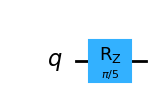

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.synthesis import generate_basic_approximations
from qiskit.transpiler.passes import SolovayKitaev
from qiskit.transpiler import PassManager
theta = np.pi / 5 # Continuous rotation angle
qc_orig = QuantumCircuit(1, name="Original_NISQ")
qc_orig.rz(theta, 0)
print(f"Original Circuit Depth: {qc_orig.depth()}")
qc_orig.draw(output='mpl')

In [5]:
basis_gates = ['h', 's', 't', 'tdg']
print("Generating basic approximation lookup table...")
approx_table = generate_basic_approximations(basis_gates, depth=3)
print(f"Approximation table generated with {len(approx_table)} sequences.")

Generating basic approximation lookup table...
Approximation table generated with 33 sequences.


C:\Users\USER\AppData\Local\Temp\ipykernel_9444\198476145.py:5: DeprecationWarning: The function ``qiskit.synthesis.discrete_basis.generate_basis_approximations.generate_basic_approximations()`` is deprecated as of Qiskit 2.3. It will be removed no earlier than 3 months after the release date. Use the SolovayKitaevDecomposition class directly, to generate, store, and load the basic approximations.
  approx_table = generate_basic_approximations(basis_gates, depth=3)


Compiled FTQC Circuit Depth: 1


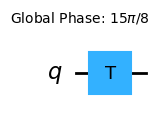

In [6]:
recursion_deg = 2
sk_pass = SolovayKitaev(recursion_degree=recursion_deg, basic_approximations=approx_table)
pass_manager = PassManager([sk_pass])
qc_ftqc = pass_manager.run(qc_orig)
print(f"Compiled FTQC Circuit Depth: {qc_ftqc.depth()}")
qc_ftqc.draw(output='mpl')

In [7]:
gate_counts = qc_ftqc.count_ops()
t_count = gate_counts.get('t', 0) + gate_counts.get('tdg', 0)
h_count = gate_counts.get('h', 0)
s_count = gate_counts.get('s', 0)
print("="*40)
print("FAULT-TOLERANT COMPILATION REPORT")
print("="*40)
print(f"Original Depth : {qc_orig.depth()}")
print(f"FTQC Depth : {qc_ftqc.depth()}")
print(f"Total Gates : {sum(gate_counts.values())}")
print(f"Logical T-Count : {t_count}")
print(f"Clifford Gates (H, S) : {h_count + s_count}")
print("Gate Breakdown :", dict(gate_counts))
print("="*40)

FAULT-TOLERANT COMPILATION REPORT
Original Depth : 1
FTQC Depth : 1
Total Gates : 1
Logical T-Count : 1
Clifford Gates (H, S) : 0
Gate Breakdown : {'t': 1}


In [1]:
!git add Day_2_FTQC_Synthesis.ipynb
!git commit -m "Day 2: Implemented Solovay-Kitaev Clifford+T synthesis and T-count extraction"

fatal: Unable to create 'C:/Users/USER/.git/index.lock': File exists.

Another git process seems to be running in this repository, e.g.
an editor opened by 'git commit'. Please make sure all processes
are terminated then try again. If it still fails, a git process
may have crashed in this repository earlier:
remove the file manually to continue.
fatal: Unable to create 'C:/Users/USER/.git/index.lock': File exists.

Another git process seems to be running in this repository, e.g.
an editor opened by 'git commit'. Please make sure all processes
are terminated then try again. If it still fails, a git process
may have crashed in this repository earlier:
remove the file manually to continue.
